In [2]:

# CELL 14A: Diagnose Global Checkpoint Path
# AGGREGATOR NOTEBOOK ONLY

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

MYDRIVE = Path("/content/drive/MyDrive")

print("=" * 65)
print("NEUROLENS — GLOBAL CHECKPOINT PATH DIAGNOSTIC")
print("=" * 65)

print("\nMyDrive accessible:", MYDRIVE.exists())

# Check the expected location first.
expected = MYDRIVE / "Mega Project" / "global_models"

print("\nExpected directory:", expected)
print("Directory exists:", expected.exists())

if expected.exists():
    print("\nFiles in expected directory:")
    for p in expected.iterdir():
        print(" -", p.name)

# Search for the checkpoint under MyDrive.
print("\nSearching MyDrive for Round 0 checkpoint...")

matches = list(
    MYDRIVE.rglob("global_model_round_000.pth")
)

if matches:
    for p in matches:
        print("FOUND:", p)
else:
    print("Checkpoint not found under MyDrive.")

# Check common alternative project-folder locations.
print("\nTop-level MyDrive folders:")
for p in sorted(MYDRIVE.iterdir()):
    if p.is_dir() and (
        "mega" in p.name.lower()
        or "global" in p.name.lower()
        or "neuro" in p.name.lower()
    ):
        print(" -", p)


Mounted at /content/drive
NEUROLENS — GLOBAL CHECKPOINT PATH DIAGNOSTIC

MyDrive accessible: True

Expected directory: /content/drive/MyDrive/Mega Project/global_models
Directory exists: True

Files in expected directory:
 - global_model_round_000.pth
 - global_model_round_000.json

Searching MyDrive for Round 0 checkpoint...
FOUND: /content/drive/MyDrive/Mega Project/global_models/global_model_round_000.pth

Top-level MyDrive folders:
 - /content/drive/MyDrive/Mega Project


In [3]:

# CELL 14: Validate All Hospital Exports
# RUN ONCE IN THE AGGREGATOR NOTEBOOK

from pathlib import Path
import torch
import json
import hashlib

PROJECT_DIR = Path("/content/drive/MyDrive/Mega Project")
GLOBAL_DIR = PROJECT_DIR / "global_models"
HOSPITALS_DIR = PROJECT_DIR / "hospital_outputs"

GLOBAL_CHECKPOINT = GLOBAL_DIR / "global_model_round_000.pth"
GLOBAL_METADATA = GLOBAL_DIR / "global_model_round_000.json"

CLIENT_IDS = ["hospital_1", "hospital_2", "hospital_3"]

EXPECTED_CLASSES = {
    "Mild Dementia": 0,
    "Moderate Dementia": 1,
    "Non Demented": 2,
    "Very mild Dementia": 3
}

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

assert GLOBAL_CHECKPOINT.exists(), "Round 0 checkpoint missing."
assert GLOBAL_METADATA.exists(), "Round 0 metadata missing."

with open(GLOBAL_METADATA, "r", encoding="utf-8") as f:
    global_metadata = json.load(f)

global_hash = sha256_file(GLOBAL_CHECKPOINT)
assert global_hash == global_metadata["checkpoint_sha256"], (
    "Global checkpoint checksum mismatch."
)

global_state = torch.load(
    GLOBAL_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert global_state["classifier.weight"].shape == (4, 1024)

client_states = {}
client_metadata = {}

for client_id in CLIENT_IDS:
    client_dir = HOSPITALS_DIR / client_id
    weights_path = client_dir / "client_weights.pth"
    metadata_path = client_dir / "client_metadata.json"

    assert weights_path.exists(), (
        f"{client_id}: missing {weights_path}"
    )
    assert metadata_path.exists(), (
        f"{client_id}: missing {metadata_path}"
    )

    with open(metadata_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    assert metadata["client_id"] == client_id, (
        f"{client_id}: client ID mismatch."
    )
    assert metadata["round"] == 1, (
        f"{client_id}: incorrect round number."
    )
    assert metadata["base_model_version"] == "global_model_round_000", (
        f"{client_id}: unexpected base model version."
    )
    assert metadata["class_to_idx"] == EXPECTED_CLASSES, (
        f"{client_id}: class mapping mismatch."
    )
    assert metadata["num_train_examples"] > 0, (
        f"{client_id}: invalid training-example count."
    )

    actual_hash = sha256_file(weights_path)
    assert actual_hash == metadata["checkpoint_sha256"], (
        f"{client_id}: exported weights checksum mismatch."
    )

    state = torch.load(
        weights_path,
        map_location="cpu",
        weights_only=True
    )

    assert state.keys() == global_state.keys(), (
        f"{client_id}: model parameter keys differ."
    )

    for key in global_state:
        assert state[key].shape == global_state[key].shape, (
            f"{client_id}: tensor shape mismatch for {key}."
        )
        assert torch.isfinite(state[key]).all(), (
            f"{client_id}: non-finite values in {key}."
        )

    client_states[client_id] = state
    client_metadata[client_id] = metadata

    print(
        f"{client_id}: PASS | "
        f"Train samples: {metadata['num_train_examples']:,} | "
        f"Weight size: {weights_path.stat().st_size / (1024**2):.2f} MB"
    )

print("\n" + "=" * 65)
print("ALL THREE CLIENT EXPORTS PASSED STRUCTURAL VALIDATION")
print("Global Round 0 SHA-256:", global_hash)
print("Aggregation has NOT started yet.")
print("=" * 65)


hospital_1: PASS | Train samples: 22,769 | Weight size: 27.09 MB
hospital_2: PASS | Train samples: 23,623 | Weight size: 27.09 MB
hospital_3: PASS | Train samples: 23,073 | Weight size: 27.09 MB

ALL THREE CLIENT EXPORTS PASSED STRUCTURAL VALIDATION
Global Round 0 SHA-256: 5c35dbf9eafa1ef1c923b603d2d44318aadd3abf2756275b0fd159ff0c9cc754
Aggregation has NOT started yet.


In [4]:

# CELL 15: Federated Averaging (FedAvg)
# RUN ONCE IN THE AGGREGATOR NOTEBOOK

from pathlib import Path
import torch
import json
import hashlib
from datetime import datetime, timezone

PROJECT_DIR = Path("/content/drive/MyDrive/Mega Project")
GLOBAL_DIR = PROJECT_DIR / "global_models"
HOSPITALS_DIR = PROJECT_DIR / "hospital_outputs"

ROUND0_PATH = GLOBAL_DIR / "global_model_round_000.pth"
ROUND0_META_PATH = GLOBAL_DIR / "global_model_round_000.json"

ROUND1_PATH = GLOBAL_DIR / "global_model_round_001.pth"
ROUND1_META_PATH = GLOBAL_DIR / "global_model_round_001.json"

CLIENT_IDS = ["hospital_1", "hospital_2", "hospital_3"]

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Never overwrite a previously generated Round 1.
if ROUND1_PATH.exists() or ROUND1_META_PATH.exists():
    raise FileExistsError(
        "Round 1 output already exists. Stop and inspect it before "
        "attempting another aggregation."
    )

assert ROUND0_PATH.exists(), "Round 0 checkpoint missing."
assert ROUND0_META_PATH.exists(), "Round 0 metadata missing."

with open(ROUND0_META_PATH, "r", encoding="utf-8") as f:
    round0_metadata = json.load(f)

round0_hash = sha256_file(ROUND0_PATH)
assert round0_hash == round0_metadata["checkpoint_sha256"], (
    "Round 0 checksum mismatch."
)

global_state = torch.load(
    ROUND0_PATH, map_location="cpu", weights_only=True
)

client_states = {}
sample_counts = {}
client_hashes = {}

# Revalidate each client before aggregation.
for client_id in CLIENT_IDS:
    client_dir = HOSPITALS_DIR / client_id
    weights_path = client_dir / "client_weights.pth"
    metadata_path = client_dir / "client_metadata.json"

    assert weights_path.exists(), f"Missing weights for {client_id}."
    assert metadata_path.exists(), f"Missing metadata for {client_id}."

    with open(metadata_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    assert metadata["client_id"] == client_id
    assert metadata["round"] == 1
    assert metadata["base_model_version"] == "global_model_round_000"
    assert metadata["num_classes"] == 4

    actual_hash = sha256_file(weights_path)
    assert actual_hash == metadata["checkpoint_sha256"], (
        f"{client_id}: checksum mismatch."
    )

    state = torch.load(
        weights_path, map_location="cpu", weights_only=True
    )

    assert state.keys() == global_state.keys(), (
        f"{client_id}: state dictionary keys differ."
    )

    for key in global_state:
        assert state[key].shape == global_state[key].shape, (
            f"{client_id}: tensor shape mismatch at {key}."
        )
        assert torch.isfinite(state[key]).all(), (
            f"{client_id}: non-finite tensor at {key}."
        )

    client_states[client_id] = state
    sample_counts[client_id] = int(metadata["num_train_examples"])
    client_hashes[client_id] = actual_hash

total_samples = sum(sample_counts.values())
assert total_samples > 0

weights = {
    client_id: count / total_samples
    for client_id, count in sample_counts.items()
}

print("Client sample counts:", sample_counts)
print("Total training samples:", total_samples)
print("FedAvg coefficients:")
for client_id in CLIENT_IDS:
    print(f"  {client_id}: {weights[client_id]:.6f}")

# Weighted average of floating-point model parameters and buffers.
# Non-floating buffers must agree; otherwise retain the Round 0 value.
aggregated_state = {}

for key, base_tensor in global_state.items():
    if torch.is_floating_point(base_tensor) or torch.is_complex(base_tensor):
        accumulator = torch.zeros_like(base_tensor)

        for client_id in CLIENT_IDS:
            accumulator += (
                client_states[client_id][key].to(base_tensor.dtype)
                * weights[client_id]
            )

        aggregated_state[key] = accumulator
    else:
        # Integer buffers (e.g., BatchNorm counters) cannot be
        # meaningfully averaged. Require agreement across clients.
        all_equal = all(
            torch.equal(client_states[cid][key], client_states[CLIENT_IDS[0]][key])
            for cid in CLIENT_IDS
        )

        if all_equal:
            aggregated_state[key] = client_states[CLIENT_IDS[0]][key].clone()
        else:
            raise ValueError(
                f"Non-floating buffer differs across clients: {key}. "
                "Investigate before aggregation."
            )

# Final sanity check.
for key, tensor in aggregated_state.items():
    assert torch.isfinite(tensor).all(), (
        f"Aggregated tensor contains non-finite values: {key}"
    )

# Save new global checkpoint without touching Round 0.
torch.save(aggregated_state, ROUND1_PATH)

round1_hash = sha256_file(ROUND1_PATH)

round1_metadata = {
    "project": "NeuroLens",
    "model_name": "DenseNet121",
    "round": 1,
    "parent_model": "global_model_round_000.pth",
    "parent_sha256": round0_hash,
    "aggregation_method": "FedAvg",
    "client_ids": CLIENT_IDS,
    "sample_counts": sample_counts,
    "total_training_samples": total_samples,
    "aggregation_weights": weights,
    "client_checkpoint_sha256": client_hashes,
    "checkpoint_sha256": round1_hash,
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

with open(ROUND1_META_PATH, "w", encoding="utf-8") as f:
    json.dump(round1_metadata, f, indent=2)

# Reload and verify the saved artifact.
reloaded = torch.load(
    ROUND1_PATH, map_location="cpu", weights_only=True
)

assert reloaded.keys() == global_state.keys()
for key in global_state:
    assert reloaded[key].shape == global_state[key].shape

print("\n" + "=" * 65)
print("FEDAVG COMPLETE — GLOBAL ROUND 1 CREATED")
print("=" * 65)
print("Checkpoint:", ROUND1_PATH)
print("Metadata:", ROUND1_META_PATH)
print("Checkpoint size (MB):", round(ROUND1_PATH.stat().st_size / (1024**2), 2))
print("Round 1 SHA-256:", round1_hash)
print("Round 0 preserved:", ROUND0_PATH.exists())
print("Saved checkpoint verified successfully.")


Client sample counts: {'hospital_1': 22769, 'hospital_2': 23623, 'hospital_3': 23073}
Total training samples: 69465
FedAvg coefficients:
  hospital_1: 0.327777
  hospital_2: 0.340071
  hospital_3: 0.332153

FEDAVG COMPLETE — GLOBAL ROUND 1 CREATED
Checkpoint: /content/drive/MyDrive/Mega Project/global_models/global_model_round_001.pth
Metadata: /content/drive/MyDrive/Mega Project/global_models/global_model_round_001.json
Checkpoint size (MB): 27.1
Round 1 SHA-256: 2edb86fe68e5ae29af5bd70eebb5b0262cc6abc698e90b1c7db91a4f5dbca360
Round 0 preserved: True
Saved checkpoint verified successfully.


In [6]:

# CELL 16 — VERIFY GLOBAL ROUND 1
# Run in the FEDERATED SERVER / AGGREGATOR notebook only.

from pathlib import Path
import hashlib
import json
import torch

PROJECT_DIR = Path("/content/drive/MyDrive/Mega Project")
GLOBAL_DIR = PROJECT_DIR / "global_models"

ROUND0_PATH = GLOBAL_DIR / "global_model_round_000.pth"
ROUND1_PATH = GLOBAL_DIR / "global_model_round_001.pth"
ROUND1_META_PATH = GLOBAL_DIR / "global_model_round_001.json"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# 1. Confirm all required files exist
assert ROUND0_PATH.exists(), "Global Round 0 checkpoint is missing!"
assert ROUND1_PATH.exists(), "Global Round 1 checkpoint is missing!"
assert ROUND1_META_PATH.exists(), "Round 1 metadata is missing!"

# 2. Load both checkpoints
round0_state = torch.load(
    ROUND0_PATH, map_location="cpu", weights_only=True
)
round1_state = torch.load(
    ROUND1_PATH, map_location="cpu", weights_only=True
)

# 3. Verify architecture/state-dict compatibility
assert round0_state.keys() == round1_state.keys(), \
    "ERROR: Round 0 and Round 1 state-dict keys differ!"

for key in round0_state:
    assert round0_state[key].shape == round1_state[key].shape, \
        f"Shape mismatch: {key}"

    tensor = round1_state[key]
    if torch.is_floating_point(tensor) or torch.is_complex(tensor):
        assert torch.isfinite(tensor).all(), \
            f"Non-finite values found in {key}"

# 4. Confirm DenseNet121's four-class output layer
assert round1_state["classifier.weight"].shape == (4, 1024)
assert round1_state["classifier.bias"].shape == (4,)

# 5. Read metadata and calculate the checkpoint checksum
with open(ROUND1_META_PATH, "r") as f:
    round1_meta = json.load(f)

round1_hash = sha256_file(ROUND1_PATH)

print("=" * 65)
print("NEUROLENS — GLOBAL ROUND 1 VERIFICATION")
print("=" * 65)
print("Round 0 exists:             ", ROUND0_PATH.exists())
print("Round 1 exists:             ", ROUND1_PATH.exists())
print("Metadata exists:            ", ROUND1_META_PATH.exists())
print("State-dict keys match:      ", True)
print("All tensor shapes match:    ", True)
print("All floating tensors finite:", True)
print("4-class classifier verified:", True)
print("Number of state-dict tensors:", len(round1_state))
print("Round 1 size (MB):           ",
      ROUND1_PATH.stat().st_size / (1024 ** 2))
print("Round 1 SHA-256:             ", round1_hash)
print("\nMetadata contents:")
print(json.dumps(round1_meta, indent=2, default=str))
print("\nGLOBAL ROUND 1 STRUCTURAL VERIFICATION PASSED")


NEUROLENS — GLOBAL ROUND 1 VERIFICATION
Round 0 exists:              True
Round 1 exists:              True
Metadata exists:             True
State-dict keys match:       True
All tensor shapes match:     True
All floating tensors finite: True
4-class classifier verified: True
Number of state-dict tensors: 727
Round 1 size (MB):            27.095340728759766
Round 1 SHA-256:              2edb86fe68e5ae29af5bd70eebb5b0262cc6abc698e90b1c7db91a4f5dbca360

Metadata contents:
{
  "project": "NeuroLens",
  "model_name": "DenseNet121",
  "round": 1,
  "parent_model": "global_model_round_000.pth",
  "parent_sha256": "5c35dbf9eafa1ef1c923b603d2d44318aadd3abf2756275b0fd159ff0c9cc754",
  "aggregation_method": "FedAvg",
  "client_ids": [
    "hospital_1",
    "hospital_2",
    "hospital_3"
  ],
  "sample_counts": {
    "hospital_1": 22769,
    "hospital_2": 23623,
    "hospital_3": 23073
  },
  "total_training_samples": 69465,
  "aggregation_weights": {
    "hospital_1": 0.32777657813287264,
    "

NEUROLENS — FEDERATED LEARNING DASHBOARD
Status: Global Round 1 aggregated and verified
Aggregation: FedAvg
Participating hospitals: 3
Total training samples: 69,465
Round 0 checkpoint: 27.10 MB
Round 1 checkpoint: 27.10 MB
Round 1 SHA-256: 2edb86fe68e5ae29af5bd70eebb5b0262cc6abc698e90b1c7db91a4f5dbca360

Client contribution summary:


,Hospital,Training samples,FedAvg weight (%)
0,hospital_1,22769,32.7777
1,hospital_2,23623,34.0071
2,hospital_3,23073,33.2153


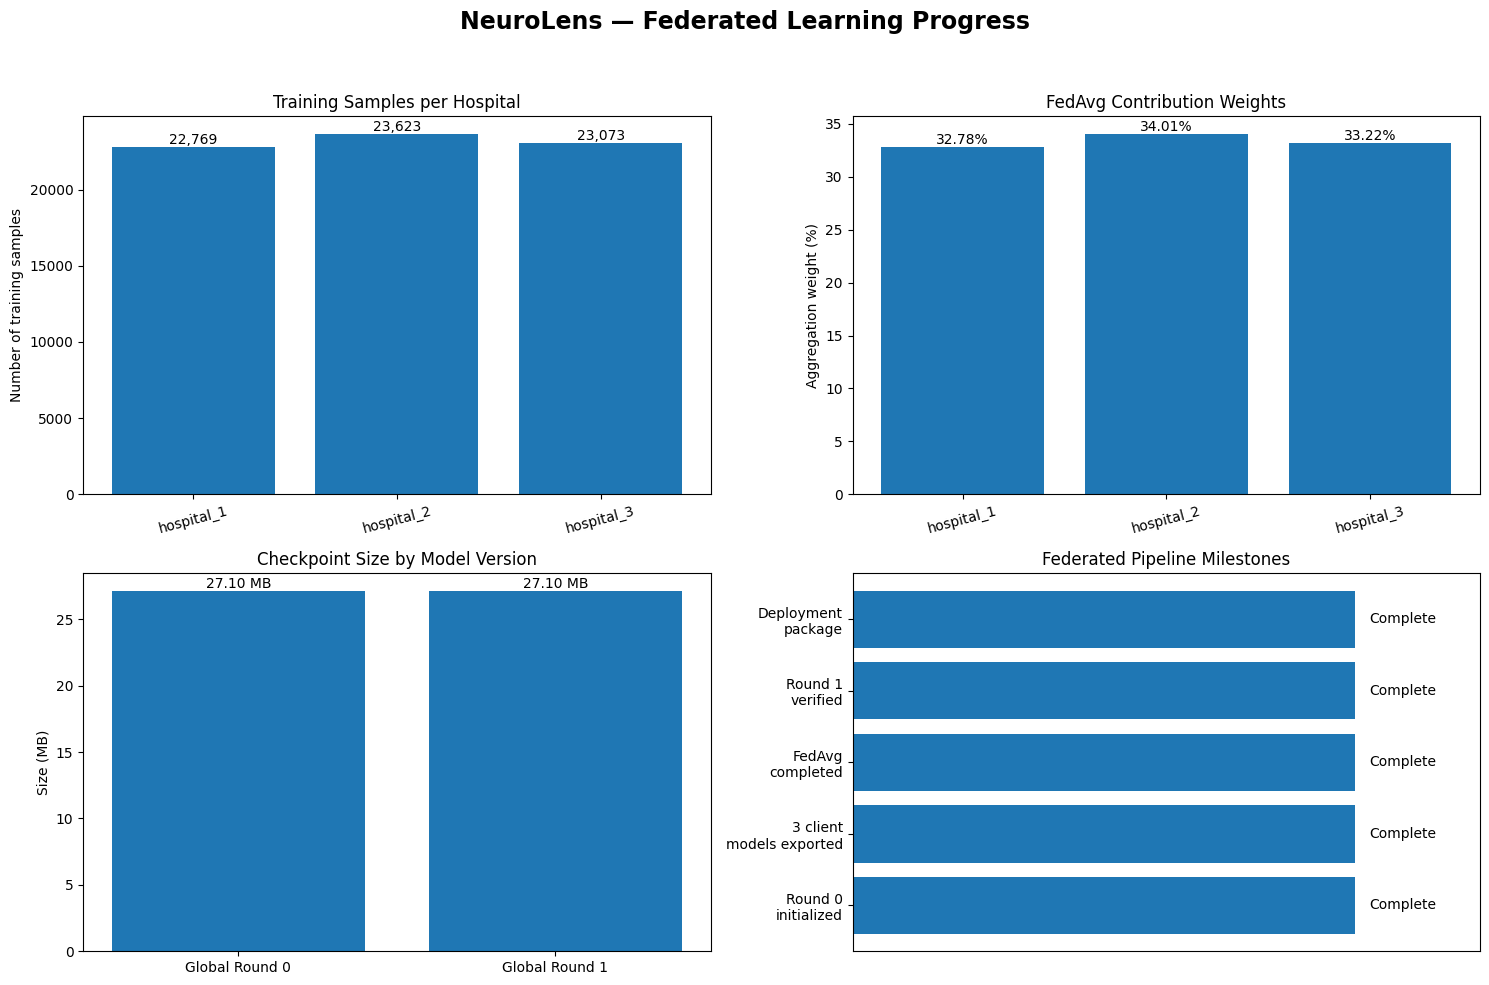

Dashboard image saved to: /content/drive/MyDrive/Mega Project/federated_dashboard/neurolens_federated_dashboard.png

NEUROLENS DEPLOYMENT PACKAGE READY
Package folder: /content/drive/MyDrive/Mega Project/deployment/neurolens_global_round_001
ZIP package: /content/drive/MyDrive/Mega Project/deployment/neurolens_global_round_001.zip
ZIP size (MB): 25.31
Dashboard folder: /content/drive/MyDrive/Mega Project/federated_dashboard
No additional training was performed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

# CELL 17 — NEUROLENS FEDERATED DASHBOARD + MODEL EXPORT
# Run in the FEDERATED SERVER / AGGREGATOR notebook only.
# No training. No new federated round.

from pathlib import Path
import json
import hashlib
import shutil
import zipfile
from datetime import datetime, timezone

import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------------------------------------------------------
# 1. PATHS
# ---------------------------------------------------------
PROJECT_DIR = Path("/content/drive/MyDrive/Mega Project")
GLOBAL_DIR = PROJECT_DIR / "global_models"

ROUND0_PATH = GLOBAL_DIR / "global_model_round_000.pth"
ROUND1_PATH = GLOBAL_DIR / "global_model_round_001.pth"
ROUND0_META_PATH = GLOBAL_DIR / "global_model_round_000.json"
ROUND1_META_PATH = GLOBAL_DIR / "global_model_round_001.json"

DASHBOARD_DIR = PROJECT_DIR / "federated_dashboard"
PACKAGE_DIR = PROJECT_DIR / "deployment" / "neurolens_global_round_001"
ZIP_PATH = PROJECT_DIR / "deployment" / "neurolens_global_round_001.zip"

DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH.parent.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 2. VERIFY INPUTS BEFORE EXPORTING
# ---------------------------------------------------------
for path in [ROUND0_PATH, ROUND1_PATH, ROUND1_META_PATH]:
    assert path.exists(), f"Required file is missing: {path}"

with open(ROUND1_META_PATH, "r") as f:
    metadata = json.load(f)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

round0_hash = sha256_file(ROUND0_PATH)
round1_hash = sha256_file(ROUND1_PATH)

assert metadata["checkpoint_sha256"] == round1_hash, \
    "Round 1 checksum mismatch. Export cancelled."

round0_state = torch.load(
    ROUND0_PATH, map_location="cpu", weights_only=True
)
round1_state = torch.load(
    ROUND1_PATH, map_location="cpu", weights_only=True
)

assert round0_state.keys() == round1_state.keys()
assert round1_state["classifier.weight"].shape == (4, 1024)

# ---------------------------------------------------------
# 3. PREPARE FEDERATED LEARNING DATA
# ---------------------------------------------------------
client_ids = metadata["client_ids"]
sample_counts = metadata["sample_counts"]
fedavg_weights = metadata["aggregation_weights"]

samples_df = pd.DataFrame({
    "Hospital": client_ids,
    "Training samples": [sample_counts[c] for c in client_ids],
    "FedAvg weight (%)": [fedavg_weights[c] * 100 for c in client_ids],
})

total_samples = sum(sample_counts.values())
round0_size_mb = ROUND0_PATH.stat().st_size / (1024 ** 2)
round1_size_mb = ROUND1_PATH.stat().st_size / (1024 ** 2)

print("=" * 72)
print("NEUROLENS — FEDERATED LEARNING DASHBOARD")
print("=" * 72)
print("Status: Global Round 1 aggregated and verified")
print("Aggregation: FedAvg")
print("Participating hospitals:", len(client_ids))
print("Total training samples:", f"{total_samples:,}")
print("Round 0 checkpoint:", f"{round0_size_mb:.2f} MB")
print("Round 1 checkpoint:", f"{round1_size_mb:.2f} MB")
print("Round 1 SHA-256:", round1_hash)
print("\nClient contribution summary:")
display(samples_df.round(4))

# ---------------------------------------------------------
# 4. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(
    "NeuroLens — Federated Learning Progress",
    fontsize=17,
    fontweight="bold"
)

# Chart A: training samples contributed by each hospital
axes[0, 0].bar(
    samples_df["Hospital"],
    samples_df["Training samples"]
)
axes[0, 0].set_title("Training Samples per Hospital")
axes[0, 0].set_ylabel("Number of training samples")
axes[0, 0].tick_params(axis="x", rotation=15)

for i, value in enumerate(samples_df["Training samples"]):
    axes[0, 0].text(i, value, f"{value:,}", ha="center", va="bottom")

# Chart B: FedAvg aggregation coefficients
axes[0, 1].bar(
    samples_df["Hospital"],
    samples_df["FedAvg weight (%)"]
)
axes[0, 1].set_title("FedAvg Contribution Weights")
axes[0, 1].set_ylabel("Aggregation weight (%)")
axes[0, 1].tick_params(axis="x", rotation=15)

for i, value in enumerate(samples_df["FedAvg weight (%)"]):
    axes[0, 1].text(i, value, f"{value:.2f}%", ha="center", va="bottom")

# Chart C: checkpoint sizes across model versions
axes[1, 0].bar(
    ["Global Round 0", "Global Round 1"],
    [round0_size_mb, round1_size_mb]
)
axes[1, 0].set_title("Checkpoint Size by Model Version")
axes[1, 0].set_ylabel("Size (MB)")

for i, value in enumerate([round0_size_mb, round1_size_mb]):
    axes[1, 0].text(i, value, f"{value:.2f} MB", ha="center", va="bottom")

# Chart D: completed project milestones (not accuracy)
milestones = [
    "Round 0\ninitialized",
    "3 client\nmodels exported",
    "FedAvg\ncompleted",
    "Round 1\nverified",
    "Deployment\npackage"
]
progress = [1, 1, 1, 1, 1]

axes[1, 1].barh(milestones, progress)
axes[1, 1].set_xlim(0, 1.25)
axes[1, 1].set_xticks([])
axes[1, 1].set_title("Federated Pipeline Milestones")
for i in range(len(milestones)):
    axes[1, 1].text(1.03, i, "Complete", va="center")

plt.tight_layout(rect=[0, 0, 1, 0.95])

dashboard_png = DASHBOARD_DIR / "neurolens_federated_dashboard.png"
plt.savefig(dashboard_png, dpi=180, bbox_inches="tight")
plt.show()

print("Dashboard image saved to:", dashboard_png)

# ---------------------------------------------------------
# 5. CREATE DEPLOYMENT PACKAGE
# ---------------------------------------------------------
# Copy the actual Round 1 state-dict checkpoint and its metadata.
shutil.copy2(
    ROUND1_PATH,
    PACKAGE_DIR / "global_model_round_001.pth"
)
shutil.copy2(
    ROUND1_META_PATH,
    PACKAGE_DIR / "global_model_round_001.json"
)

# Save the configuration needed to construct the model at inference.
model_config = {
    "project": "NeuroLens",
    "model_name": "DenseNet121",
    "model_version": "global_model_round_001",
    "checkpoint_format": "PyTorch state_dict",
    "num_classes": 4,
    "input_size": [224, 224],
    "color_mode": "RGB",
    "class_to_idx": {
        "Mild Dementia": 0,
        "Moderate Dementia": 1,
        "Non Demented": 2,
        "Very mild Dementia": 3
    },
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "architecture_notes": (
        "Construct torchvision DenseNet121 with weights=None, "
        "replace classifier with torch.nn.Linear(1024, 4), "
        "then load the supplied state_dict with strict=True."
    ),
    "checkpoint_sha256": round1_hash,
    "warning": (
        "Structural verification is complete; do not interpret this "
        "as proof of clinical validity or improved test accuracy."
    )
}

with open(PACKAGE_DIR / "model_config.json", "w") as f:
    json.dump(model_config, f, indent=2)

# Save a deployment README
readme = """# NeuroLens Global Model — Round 1

## Files
- global_model_round_001.pth: PyTorch model state_dict
- global_model_round_001.json: aggregation metadata and checksum
- model_config.json: architecture, class mapping and preprocessing

## Model
- Architecture: DenseNet121
- Output classes: 4
- Input: RGB image resized to 224 x 224
- Normalization mean: [0.485, 0.456, 0.406]
- Normalization std: [0.229, 0.224, 0.225]

## Class mapping
0: Mild Dementia
1: Moderate Dementia
2: Non Demented
3: Very mild Dementia

## Loading the checkpoint
Construct torchvision DenseNet121 with weights=None.
Replace model.classifier with torch.nn.Linear(1024, 4).
Load the checkpoint using model.load_state_dict(state, strict=True).
Use model.eval() for inference.

## Important
This package contains model weights, not a complete web application.
Validate model performance on independent held-out data before deployment.
This model is a research prototype, not a diagnostic medical device.
"""

(PACKAGE_DIR / "README.md").write_text(readme, encoding="utf-8")

# Include the dashboard image in the deployment package.
shutil.copy2(
    dashboard_png,
    PACKAGE_DIR / "neurolens_federated_dashboard.png"
)

# ---------------------------------------------------------
# 6. SAVE A SUMMARY REPORT
# ---------------------------------------------------------
report = {
    "project": "NeuroLens",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "status": "Global Round 1 structurally verified",
    "training_started_again": False,
    "aggregation_method": metadata["aggregation_method"],
    "client_ids": client_ids,
    "sample_counts": sample_counts,
    "total_training_samples": total_samples,
    "aggregation_weights": fedavg_weights,
    "round_0_sha256": round0_hash,
    "round_1_sha256": round1_hash,
    "round_0_checkpoint_size_mb": round0_size_mb,
    "round_1_checkpoint_size_mb": round1_size_mb,
    "evaluation_note": (
        "This report documents aggregation and structural verification. "
        "It does not claim that global test accuracy improved."
    )
}

with open(DASHBOARD_DIR / "federated_progress_report.json", "w") as f:
    json.dump(report, f, indent=2)

samples_df.to_csv(
    DASHBOARD_DIR / "client_contributions.csv",
    index=False
)

shutil.copy2(
    dashboard_png,
    PACKAGE_DIR / "neurolens_federated_dashboard.png"
)

# ---------------------------------------------------------
# 7. ZIP THE DEPLOYMENT PACKAGE
# ---------------------------------------------------------
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for file_path in PACKAGE_DIR.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.relative_to(PACKAGE_DIR))

print("\n" + "=" * 72)
print("NEUROLENS DEPLOYMENT PACKAGE READY")
print("=" * 72)
print("Package folder:", PACKAGE_DIR)
print("ZIP package:", ZIP_PATH)
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024 ** 2), 2))
print("Dashboard folder:", DASHBOARD_DIR)
print("No additional training was performed.")

# Trigger download in Google Colab.
from google.colab import files
files.download(str(ZIP_PATH))
